# 01 - Exploratory Data Analysis

Data source: reporting views in the `rpt` schema of **OlistDB** (SQL Server).
All business rules (delivered orders only, revenue excluding freight, customer = `customer_unique_id`) live in the SQL views, so Python and Power BI report the same numbers.


## 1. Connection test


In [18]:
import pandas as pd
from db_utils import run_query

# Who am I connected as, and to which database?
run_query("""
    SELECT DB_NAME()      AS db,
           SUSER_NAME()   AS login_user,
           @@SERVERNAME   AS server_name,
           CAST(SERVERPROPERTY('ProductVersion') AS varchar(20)) AS sql_version
""")

,db,login_user,server_name,sql_version
0,OlistDB,MSI\ms,MSI\SQLEXPRESS,17.0.1000.7


## 2. Load the reporting views

In [19]:
# List every column in the rpt views (name + SQL data type)
cols = run_query("""
    SELECT TABLE_NAME AS view_name, COLUMN_NAME AS column_name, DATA_TYPE AS data_type
    FROM INFORMATION_SCHEMA.COLUMNS
    WHERE TABLE_SCHEMA = 'rpt'
    ORDER BY TABLE_NAME, ORDINAL_POSITION
""")
print(cols.to_string(index=False))

         view_name        column_name data_type
 vw_CohortActivity       customer_key       int
 vw_CohortActivity       cohort_month  nvarchar
 vw_CohortActivity     activity_month  nvarchar
 vw_CohortActivity       month_number       int
 vw_CustomerOrders           order_id   varchar
 vw_CustomerOrders       customer_key       int
 vw_CustomerOrders customer_unique_id   varchar
 vw_CustomerOrders     customer_state   varchar
 vw_CustomerOrders        purchase_ts datetime2
 vw_CustomerOrders      purchase_date      date
 vw_CustomerOrders     purchase_month      char
 vw_CustomerOrders          order_seq    bigint
 vw_CustomerOrders         item_count       int
 vw_CustomerOrders            revenue   decimal
 vw_CustomerOrders      freight_value   decimal
 vw_CustomerOrders      payment_value   decimal
 vw_CustomerOrders      delivery_days       int
 vw_CustomerOrders         delay_days       int
 vw_CustomerOrders            is_late       bit
 vw_CustomerOrders       review_score   

In [20]:
from db_utils import read_view

views = ["vw_CustomerOrders", "vw_CustomerSummary", "vw_CohortActivity", "vw_MonthlyKPIs"]
data = {v: read_view(v) for v in views}   # dict: view name -> DataFrame

for name, df in data.items():
    print(f"{name:<20} rows={len(df):>8,}  cols={df.shape[1]}")

vw_CustomerOrders    rows=  96,470  cols=16
vw_CustomerSummary   rows=  93,350  cols=12
vw_CohortActivity    rows=  95,186  cols=4
vw_MonthlyKPIs       rows=      23  cols=8


In [21]:
# Python must reproduce the same totals we validated in SQL (Phase 1)
checks = {
    "Delivered orders": (len(data["vw_CustomerOrders"]), 96_470),
    "Unique customers": (len(data["vw_CustomerSummary"]), 93_350),
}
for label, (actual, expected) in checks.items():
    status = "OK" if actual == expected else "MISMATCH"
    print(f"{status:<9} {label}: {actual:,} (expected {expected:,})")

OK        Delivered orders: 96,470 (expected 96,470)
OK        Unique customers: 93,350 (expected 93,350)


In [22]:
# Revenue must match Phase 1 in every view (revenue excludes freight)
EXPECTED_REVENUE = 13_220_248.93
totals = {
    "vw_CustomerOrders":  data["vw_CustomerOrders"]["revenue"].sum(),
    "vw_CustomerSummary": data["vw_CustomerSummary"]["revenue"].sum(),
    "vw_MonthlyKPIs":     data["vw_MonthlyKPIs"]["revenue"].sum(),
}
for name, total in totals.items():
    status = "OK" if round(total, 2) == EXPECTED_REVENUE else "MISMATCH"
    print(f"{status:<9} {name:<20} {total:,.2f}")

# Money columns should arrive as numbers (float64), not object
print()
print(data["vw_CustomerOrders"][["revenue", "freight_value", "payment_value", "purchase_ts", "purchase_date"]].dtypes)

OK        vw_CustomerOrders    13,220,248.93
OK        vw_CustomerSummary   13,220,248.93
OK        vw_MonthlyKPIs       13,220,248.93

revenue                 float64
freight_value           float64
payment_value           float64
purchase_ts      datetime64[us]
purchase_date            object
dtype: object


## 3. Prepare data for EDA

- Convert date/month columns to real datetime types.
- Analysis window: **Jan 2017 - Aug 2018**. 2016 has almost no orders, so growth rates there are meaningless.


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# One consistent chart style for the whole notebook
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.titleweight"] = "bold"

# Short names + copies, so the original data stays untouched
orders    = data["vw_CustomerOrders"].copy()
customers = data["vw_CustomerSummary"].copy()
cohort    = data["vw_CohortActivity"].copy()
monthly   = data["vw_MonthlyKPIs"].copy()

# Text / object columns -> real datetimes (format is strict: fails loudly if the data is not YYYY-MM)
orders["purchase_date"]   = pd.to_datetime(orders["purchase_date"])
orders["purchase_month"]  = pd.to_datetime(orders["purchase_month"], format="%Y-%m")
monthly["purchase_month"] = pd.to_datetime(monthly["purchase_month"], format="%Y-%m")
cohort["cohort_month"]    = pd.to_datetime(cohort["cohort_month"], format="%Y-%m")
cohort["activity_month"]  = pd.to_datetime(cohort["activity_month"], format="%Y-%m")
monthly = monthly.sort_values("purchase_month").reset_index(drop=True)

# Analysis window for time-based charts
START, END = pd.Timestamp("2017-01-01"), pd.Timestamp("2018-08-01")
monthly_win = monthly[monthly["purchase_month"].between(START, END)]

print("Order dates :", orders["purchase_date"].min().date(), "->", orders["purchase_date"].max().date())
print("Months total:", len(monthly), "| in window:", len(monthly_win))
print("Orders outside window:", (~orders["purchase_month"].between(START, END)).sum())
print()
print(orders[["purchase_date", "purchase_month"]].dtypes)

Order dates : 2016-09-15 -> 2018-08-29
Months total: 23 | in window: 20
Orders outside window: 267

purchase_date      datetime64[s]
purchase_month    datetime64[us]
dtype: object


## 4. Is the business growing?

**Question:** How did monthly revenue and order volume change between Jan 2017 and Aug 2018?


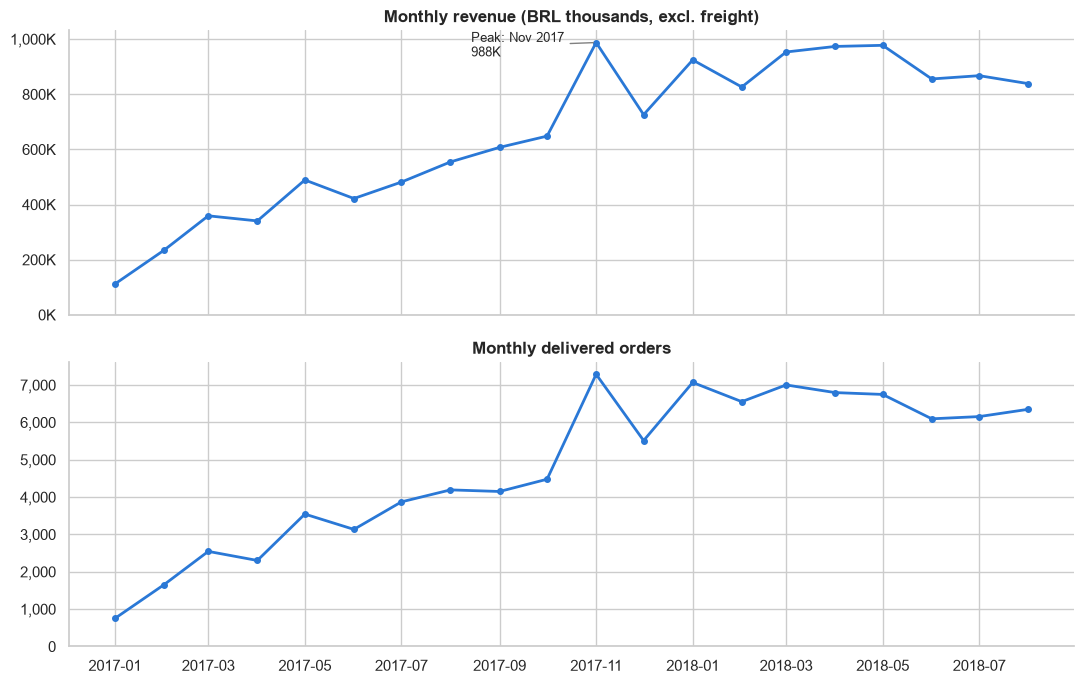

In [24]:
from pathlib import Path
import matplotlib.ticker as mtick

BLUE = "#2a78d6"                 # one hue: each panel shows a single series
IMG_DIR = Path("../images")       # charts saved here for the README
IMG_DIR.mkdir(exist_ok=True)

# Two panels sharing the time axis (never one chart with two y-axes)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

ax1.plot(monthly_win["purchase_month"], monthly_win["revenue"] / 1_000, color=BLUE, lw=2, marker="o", ms=4)
ax1.set_title("Monthly revenue (BRL thousands, excl. freight)")
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}K"))
ax1.set_ylim(bottom=0)

ax2.plot(monthly_win["purchase_month"], monthly_win["orders"], color=BLUE, lw=2, marker="o", ms=4)
ax2.set_title("Monthly delivered orders")
ax2.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax2.set_ylim(bottom=0)

# Label only the peak month (selective direct label)
peak = monthly_win.loc[monthly_win["revenue"].idxmax()]
ax1.annotate(f"Peak: {peak['purchase_month']:%b %Y}\n{peak['revenue']/1_000:,.0f}K",
             xy=(peak["purchase_month"], peak["revenue"] / 1_000),
             xytext=(-90, -10), textcoords="offset points",
             arrowprops=dict(arrowstyle="-", color="gray"), fontsize=9)

for ax in (ax1, ax2):
    ax.set_xlabel("")
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(IMG_DIR / "01_monthly_revenue_orders.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
# Numbers behind the chart: compare the SAME months (Jan-Aug) of both years
def period(y):
    m = monthly_win[(monthly_win["purchase_month"].dt.year == y) & (monthly_win["purchase_month"].dt.month <= 8)]
    return pd.Series({"revenue": m["revenue"].sum(), "orders": m["orders"].sum(),
                      "avg_monthly_revenue": m["revenue"].mean()})

yoy = pd.DataFrame({"Jan-Aug 2017": period(2017), "Jan-Aug 2018": period(2018)})
yoy["change_%"] = (yoy["Jan-Aug 2018"] / yoy["Jan-Aug 2017"] - 1) * 100
print(yoy.round(1).to_string())

# Within 2018: is there still growth month to month?
m18 = monthly_win[monthly_win["purchase_month"].dt.year == 2018][["purchase_month", "revenue", "orders", "avg_order_value"]]
print()
print(m18.assign(purchase_month=m18["purchase_month"].dt.strftime("%Y-%m")).to_string(index=False))

                     Jan-Aug 2017  Jan-Aug 2018  change_%
revenue                 2993277.1     7217172.2     141.1
orders                    21997.0       52777.0     139.9
avg_monthly_revenue      374159.6      902146.5     141.1

purchase_month   revenue  orders  avg_order_value
       2018-01 924645.00    7069           130.80
       2018-02 826437.13    6555           126.08
       2018-03 953356.25    7003           136.14
       2018-04 973534.09    6798           143.21
       2018-05 977544.69    6749           144.84
       2018-06 855591.97    6096           140.35
       2018-07 867486.47    6156           140.92
       2018-08 838576.64    6351           132.04
